# Getting to know the data

Understanding the data is a foundational step in any machine learning project and is crucial for achieving reproducibility in research. 

One of the primary reasons why getting to know the data is essential is its direct impact on the reliability and generalizability of the machine learning models. We can identify potential biases, anomalies, or inconsistencies that may affect model performance by exploring the data. 

This understanding enables us to apply appropriate preprocessing techniques, such as [handling missing values](#data-cleaning), [addressing class imbalances](/notebooks/1-model-evaluation.html#stratification), or [feature normalisation](#pre-processing), to ensure that the model learns meaningful patterns from the data.

Moreover, gaining insights into the data can guide us as researchers in selecting the most appropriate algorithms and architectures for these tasks. Understanding the distribution and relationships within the data allows us to choose well-suited models to capture complex patterns and make accurate predictions.

This tutorial uses the [Palmer Penguins dataset](https://allisonhorst.github.io/palmerpenguins/). Data were collected and made available by [Dr. Kristen Gorman](https://www.uaf.edu/cfos/people/faculty/detail/kristen-gorman.php) and the [Palmer Station, Antarctica LTER](https://pallter.marine.rutgers.edu/), a member of the [Long Term Ecological Research Network](https://lternet.edu/).

Let's dive into some quick exploration of the data!

In [1]:
from pathlib import Path

DATA_FOLDER = Path("..", "..") / "data"
DATA_FILEPATH = DATA_FOLDER / "penguins.csv"

We'll use the `pandas` library to load an pre-process the data. It has quite a few convenience functions like loading CSVs or dropping columns. 

In [2]:
import pandas as pd

In [3]:
penguins_raw = pd.read_csv(DATA_FILEPATH)
penguins_raw.head()

,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
0,PAL0708,1,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A1,Yes,2007-11-11,39.1,18.7,181.0,3750.0,MALE,NaN,NaN,Not enough blood for isotopes.
1,PAL0708,2,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N1A2,Yes,2007-11-11,39.5,17.4,186.0,3800.0,FEMALE,8.94956,-24.69454,NaN
2,PAL0708,3,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A1,Yes,2007-11-16,40.3,18.0,195.0,3250.0,FEMALE,8.36821,-25.33302,NaN
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,2007-11-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
4,PAL0708,5,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N3A1,Yes,2007-11-16,36.7,19.3,193.0,3450.0,FEMALE,8.76651,-25.32426,NaN


We can see that this dataset has a lot more potential than your usual "toy dataset". We get the full provenance of this data including the study a penguin was measured in, where it lives, and even comments by the researchers collecting the data!

And honestly, this looks like a lot. Some of these variables might actually leak information, like the location or study number telling us what penguin colony was sampled.

Let's reduce this to some numerical columns `Culmen Length (mm)`, `Culmen Depth (mm)`, `Flipper Length (mm)`, then `Sex` as a categorical value in case penguins exhibit [sexual dimorphism](https://en.wikipedia.org/wiki/Sexual_dimorphism) and the `species` as our target column to make it easier for us.

In [4]:
num_features = ["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)"]
cat_features = ["Sex"]
features = num_features + cat_features
target = ["Species"]
penguins = penguins_raw[features+target]
penguins

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Sex,Species
0,39.1,18.7,181.0,MALE,Adelie Penguin (Pygoscelis adeliae)
1,39.5,17.4,186.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
2,40.3,18.0,195.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
3,NaN,NaN,NaN,NaN,Adelie Penguin (Pygoscelis adeliae)
4,36.7,19.3,193.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
...,...,...,...,...,...
339,55.8,19.8,207.0,MALE,Chinstrap penguin (Pygoscelis antarctica)
340,43.5,18.1,202.0,FEMALE,Chinstrap penguin (Pygoscelis antarctica)
341,49.6,18.2,193.0,MALE,Chinstrap penguin (Pygoscelis antarctica)
342,50.8,19.0,210.0,MALE,Chinstrap penguin (Pygoscelis antarctica)


Much easier to deal with for a non-expert in Penguin studies!

## Data Visualization

Data visualization is indispensable for effective data exploration in machine learning research. 

We can quickly grasp the datasets' distribution, relationships, and anomalies through visual representations like scatter plots, histograms, and box plots. These visualizations provide invaluable insights into the underlying structure of the data, enabling researchers to identify patterns, trends, and outliers that may influence model performance. 

Moreover, visualizations facilitate collaboration and communication among team members, as they provide intuitive ways to convey complex insights and findings. 

In essence, data visualization is a cornerstone of data exploration, enhancing the reproducibility and reliability of machine learning research by enabling researchers to gain a deeper understanding of their datasets.

For this visualization we'll use `seaborn` which is a statistical plotting library that makes our job much easier than the more granular `matplotlib`.

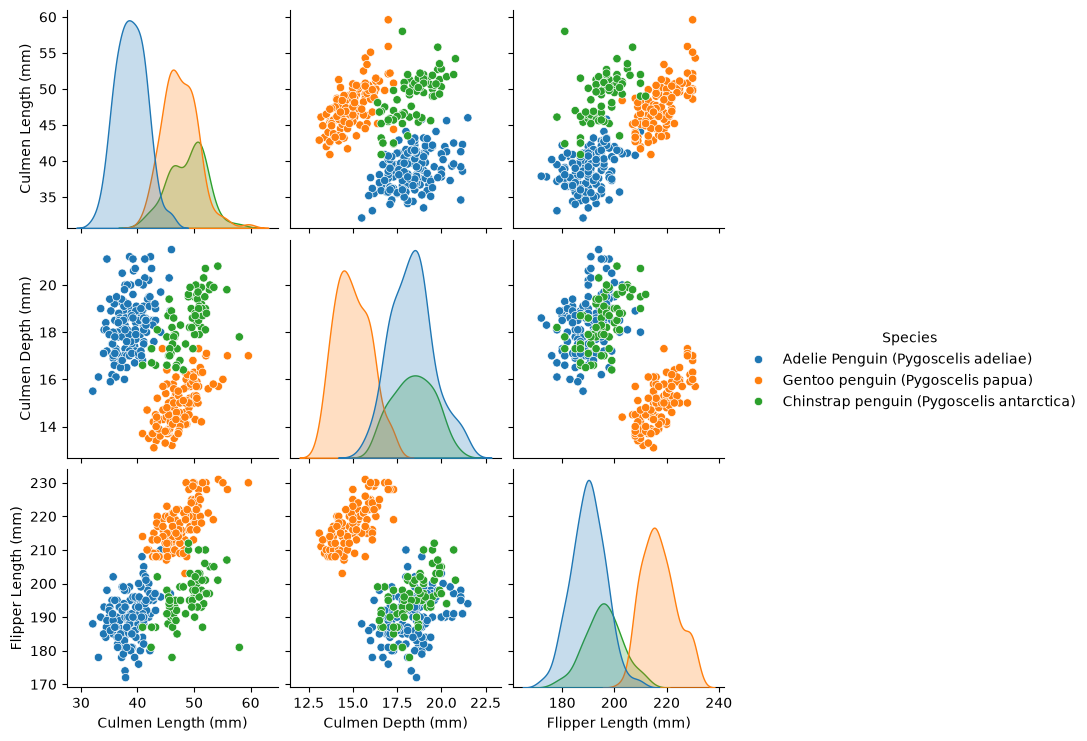

In [5]:
import seaborn as sns

pairplot_figure = sns.pairplot(penguins, hue="Species")

Looks like we're getting some good separation of the clusters already!

This promises to be a good dataset for fairly simple machine learning algorithms.

## Data cleaning

That means we can probably do some cleaning and get ready to build some good machine learning models.

Dropping NaNs, or missing values, during the data cleaning process is the most basic form of cleaning data. Some machine learning algorithms can actually process NaNs, which is a great way to deal with missing data, but in our case we're choosing the simplest way. Don't take this as the best practice though!

By removing rows or columns containing NaNs, researchers can prevent these issues and ensure that their models learn from complete and consistent data. While imputation techniques exist to fill in missing values, dropping NaNs is often preferred when the proportion of missing values is small relative to the dataset size or when imputation could introduce inaccuracies.

Sometimes we can even gain information from NaNs, when they're not "missing at random". Then we can actually pre-process the data by adding a boolean feature that encodes the "missingness" of a variable and use mean imputation on the data column.

In [6]:
penguins = penguins.dropna(axis='rows')
penguins

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Sex,Species
0,39.1,18.7,181.0,MALE,Adelie Penguin (Pygoscelis adeliae)
1,39.5,17.4,186.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
2,40.3,18.0,195.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
4,36.7,19.3,193.0,FEMALE,Adelie Penguin (Pygoscelis adeliae)
5,39.3,20.6,190.0,MALE,Adelie Penguin (Pygoscelis adeliae)
...,...,...,...,...,...
339,55.8,19.8,207.0,MALE,Chinstrap penguin (Pygoscelis antarctica)
340,43.5,18.1,202.0,FEMALE,Chinstrap penguin (Pygoscelis antarctica)
341,49.6,18.2,193.0,MALE,Chinstrap penguin (Pygoscelis antarctica)
342,50.8,19.0,210.0,MALE,Chinstrap penguin (Pygoscelis antarctica)


In [7]:
DATA_CLEAN_FILEPATH = DATA_FOLDER / "penguins_clean.csv"

penguins.to_csv(DATA_CLEAN_FILEPATH, index=False)

Not too bad it looks like we lost ten rows. That's manageable, it's a toy dataset after all.

So let's build a small model to classify penguins!

## Machine Learning

First, it's essential to split the data into separate sets for training and testing purposes. 

This split enables us to evaluate the performance of our machine learning model effectively. By training the model on a portion of the data and testing it on unseen data, we can assess whether the model has learned generalizable patterns or has simply memorized the training examples.

When a model that fails to generalize to unseen data this is known as overfitting. Overfitting is a phenomenon where the model performs well on the training data but fails on non-training data. Overfitting leads to poor performance and unreliable predictions in real-world scenarios. 

Therefore, by splitting the data, we can detect and mitigate overfitting, ensuring that our model learns meaningful patterns that generalize to unseen data.

We'll choose 70% of the data as training data here:

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(penguins[features], penguins[target], train_size=.7, random_state=39)
X_train

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Sex
202,46.6,14.2,210.0,FEMALE
250,48.4,14.4,203.0,FEMALE
169,49.2,15.2,221.0,MALE
195,49.6,15.0,216.0,MALE
316,49.0,19.5,210.0,MALE
...,...,...,...,...
235,50.0,15.9,224.0,MALE
76,40.9,16.8,191.0,FEMALE
70,33.5,19.0,190.0,FEMALE
46,41.1,19.0,182.0,MALE


In [9]:
y_train

,Species
202,Gentoo penguin (Pygoscelis papua)
250,Gentoo penguin (Pygoscelis papua)
169,Gentoo penguin (Pygoscelis papua)
195,Gentoo penguin (Pygoscelis papua)
316,Chinstrap penguin (Pygoscelis antarctica)
...,...
235,Gentoo penguin (Pygoscelis papua)
76,Adelie Penguin (Pygoscelis adeliae)
70,Adelie Penguin (Pygoscelis adeliae)
46,Adelie Penguin (Pygoscelis adeliae)


Now we can build a machine learning model.

Here we'll use the scikit-learn pipeline model. 
This makes it really easy for us to train prepocessors and models on the training data alone and cleanly apply to the test data set without leakage.


### Pre-processing

Pre-processing data is the next critical step in preparing it for machine learning models, and the scikit-learn library offers powerful tools like `StandardScaler` and `OneHotEncoder` to facilitate this process. 

The `StandardScaler` is commonly used to standardize features by removing the mean and scaling them to unit variance, ensuring that each feature contributes equally to the model's performance. This transformation is particularly beneficial for algorithms sensitive to feature scaling, such as support vector machines and k-nearest neighbours. 

On the other hand, OneHotEncoder is instrumental in handling categorical variables by converting them into a binary representation, where each category becomes a binary feature. This transformation prevents the model from interpreting categorical variables as ordinal, e.g. category `1` is "stronger" than category `0`, and ensures that all categories are treated equally.

Together, these pre-processing techniques help enhance the performance and robustness of machine learning models, ready to be fed into the model for training and evaluation.

<div class="alert alert-block alert-info">
<b>Tip:</b> In science, any type of feature selection, scaling, basically anything you do to the data, needs to be done <strong>after</strong> a split into training and test set.<br>Statistically and scientifically valid results come from proper treatment of our data. Unfortunately, we can overfit manually if we don't split out a test set before pre-processing.</div>

In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown='ignore')

The `ColumnTransformer` is a neat tool that can apply your preprocessing steps to the right columns in your dataset. 

This transformer is pretty efficient because it allows us to target individual subsets of data for transformation, ensuring that preprocessing techniques are applied only where necessary. 

Moreover, leveraging a Pipeline instead of a standalone `StandardScaler` or `ColumnTransformer` offers even greater flexibility, enabling the integration of more intricate preprocessing workflows, which we'll see further below. This versatility is particularly valuable when working on complex machine learning tasks that demand comprehensive preprocessing strategies beyond the scope of basic projects, enabling researchers to unleash the full potential of their data.

In [11]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

Ok now we'll build a reproducible `Pipeline` including a support-vector machine as the classifier!

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC()),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

We can see a nice model representation here.

You can click on the different modules that will tell you which arguments were passed into the pipeline. In our case, how we handle unknown values in the OneHotEncoder.

The `Pipeline` offers a convenient solution to prevent unintentional leakage of information from test data during preprocessing. By encapsulating preprocessing steps within a pipeline, each transformation is applied sequentially and independently to the data, ensuring that normalizers and other preprocessing techniques are fitted solely on the training data. 

This prevents the inadvertent fitting of preprocessors to the test data, mitigating the risk of information leakage and preserving the integrity of the evaluation process. One way to avoid accidents in our research!

### Model Training

Now it's time to fit our Support-Vector Machine to our training data.

This process involves training the model on the provided training data to learn patterns and relationships within the features and their corresponding labels. During the fitting process, the model adjusts its parameters to minimize the difference between its predictions and the actual target values. 

The `.fit()` method encapsulates this training process, allowing the model to learn from the training data and prepare for subsequent evaluation and prediction tasks. 

(And it's all in the `Pipeline`, which makes sure our pre-processors get fitted to the same exact data!)

In [13]:
model.fit(X_train, y_train[target[0]])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Adelie Penguin (Pygoscelis adeliae)', 'Chinstrap penguin (Pygoscelis antarctica)', 'Gentoo penguin (Pygoscelis papua)']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Culmen Length (mm)','Culmen Depth (mm)','Flipper Length (mm)','Sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the ou

We can see that we get a decent score on the training data.

This metric only tells us how well the model can perform on the data it has seen, we don't know anything about generalization and actual "learning" yet.

In [14]:
model.score(X_train, y_train)

0.9914163090128756

To evaluate how well our model learned, we check the model against the test data one final time.
<div class="alert alert-block alert-info">
<b>Tip:</b> It is possible to manually overfit a model to the test set, by tweaking the pipelines based on the test score.<br>This invalidates scientific results and must be avoided. If you need to manually tweak the model, use a three-way `train-val-test` split.<br>Only evaluate on the test set once!</div>

In [15]:
model.score(X_test, y_test)

0.9801980198019802

That's an extraordinary score! 

We can predict our penguins with 100%, so let's evaluate these models in the following pages!